# London House Price Prediction: Linear Regression Project

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

## 1. Get & understand the data

**Dataset:** London House Price Data (`London.csv`)

**Source:** Kaggle: https://www.kaggle.com/datasets/jakewright/house-price-data

**Why this dataset?**
- It covers London properties with the features the task asks about: size (`floorAreaSqM`), location (`postcode`, `outcode`, `latitude`, `longitude`), bedrooms, bathrooms, property type, tenure and energy rating.
- Each property has a **sales history** (`history_date`, `history_price`), so prices can be tracked over time. This is what we need to talk about price change from one year to the next.

In [2]:
# Pull the dataset straight from Kaggle through its API (kagglehub), instead of a local file.
import glob, os
import kagglehub

try:
    dataset_path = kagglehub.dataset_download("jakewright/house-price-data")
    print("Downloaded to:", dataset_path)

    csv_files = glob.glob(os.path.join(dataset_path, "**", "*.csv"), recursive=True)
    print("CSV files found:", [os.path.basename(f) for f in csv_files])

    london_csv = next(f for f in csv_files if os.path.basename(f).lower() == "london.csv")
    df = pd.read_csv(london_csv)
except Exception as e:
    print("API download failed:", e)
    print("Falling back to local file data/London.csv")
    df = pd.read_csv("data/London.csv")

print("Shape:", df.shape)
display(df.head())

Downloaded to: C:\Users\shaik\.cache\kagglehub\datasets\jakewright\house-price-data\versions\5
CSV files found: ['kaggle_london_house_price_data.csv']
API download failed: 
Falling back to local file data/London.csv
Shape: (418201, 28)


,fullAddress,postcode,country,outcode,latitude,longitude,bathrooms,bedrooms,floorAreaSqM,livingRooms,tenure,propertyType,currentEnergyRating,rentEstimate_lowerPrice,rentEstimate_currentPrice,rentEstimate_upperPrice,saleEstimate_lowerPrice,saleEstimate_currentPrice,saleEstimate_upperPrice,saleEstimate_confidenceLevel,saleEstimate_ingestedAt,saleEstimate_valueChange.numericChange,saleEstimate_valueChange.percentageChange,saleEstimate_valueChange.saleDate,history_date,history_price,history_percentageChange,history_numericChange
0,"Flat 9, 35 Furnival Street, London, EC4A 1JQ",EC4A 1JQ,England,EC4A,51.52,-0.11,1.00,1.00,45.00,1.00,Leasehold,Purpose Built Flat,NaN,"2,100.00","2,350.00","2,600.00","570,000.00","600,000.00","630,000.00",HIGH,2024-10-07T13:26:59.894Z,"244,000.00",68.54,2010-03-30,1995-01-02,830000,NaN,NaN
1,"Flat 6, 35 Furnival Street, London, EC4A 1JQ",EC4A 1JQ,England,EC4A,51.52,-0.11,NaN,NaN,NaN,NaN,Leasehold,Flat/Maisonette,NaN,"2,100.00","2,350.00","2,600.00","540,000.00","600,000.00","660,000.00",MEDIUM,2024-10-07T13:26:59.894Z,"425,000.00",242.86,2000-05-26,1995-01-02,830000,NaN,NaN
2,"Flat 35, Octavia House, Medway Street, London,...",SW1P 2TA,England,SW1P,51.50,-0.13,2.00,2.00,71.00,1.00,Leasehold,Flat/Maisonette,C,"2,650.00","2,950.00","3,250.00","683,000.00","759,000.00","834,000.00",MEDIUM,2025-01-10T11:04:57.114Z,"49,000.00",6.90,2019-09-04,1995-01-03,249950,NaN,NaN
3,"24 Chester Court, Lomond Grove, London, SE5 7HS",SE5 7HS,England,SE5,51.48,-0.09,1.00,1.00,64.00,1.00,Leasehold,Flat/Maisonette,D,"1,850.00","2,000.00","2,100.00","368,000.00","388,000.00","407,000.00",HIGH,2024-10-07T13:26:59.894Z,"28,000.00",7.78,2024-01-25,1995-01-03,32000,NaN,NaN
4,"18 Alexandra Gardens, London, N10 3RL",N10 3RL,England,N10,51.59,-0.14,1.00,4.00,137.00,2.00,Freehold,End Terrace House,D,"4,350.00","4,850.00","5,350.00","1,198,000.00","1,261,000.00","1,324,000.00",HIGH,2024-10-07T13:26:59.894Z,"81,000.00",6.86,2022-12-14,1995-01-03,133000,NaN,NaN


**Explanation:** Calls the Kaggle API to download the dataset, finds `London.csv` in the downloaded folder and reads it. It then prints the size and the first five rows. You should see about 418,000 rows and 28 columns. The `try/except` falls back to a local copy if the API call fails.

**Explanation:** Lists every column with its data type and non-null count. It gives a first view of missing data and shows which columns are numbers and which are text.

In [4]:
# Summary of the numeric columns and the number of unique values in the key text columns
display(df.describe().T)
print()
for col in ["propertyType", "tenure", "currentEnergyRating", "outcode"]:
    print(f"{col}: {df[col].nunique()} unique values")
print("Unique properties (by address):", df["fullAddress"].nunique())

,count,mean,std,min,25%,50%,75%,max
latitude,"418,201.00",51.51,0.06,51.39,51.46,51.50,51.55,51.67
longitude,"418,201.00",-0.10,0.09,-0.35,-0.16,-0.11,-0.04,0.14
bathrooms,"340,270.00",1.44,0.72,1.00,1.00,1.00,2.00,9.00
bedrooms,"377,665.00",2.47,1.16,1.00,2.00,2.00,3.00,9.00
floorAreaSqM,"392,991.00",98.93,55.94,10.00,63.00,84.00,116.00,500.00
livingRooms,"357,701.00",1.28,0.57,1.00,1.00,1.00,1.00,9.00
rentEstimate_lowerPrice,"416,460.00","3,299.05","3,168.63",300.00,"1,800.00","2,350.00","3,550.00","111,500.00"
rentEstimate_currentPrice,"416,460.00","3,639.49","3,487.80",350.00,"1,950.00","2,600.00","3,950.00","121,200.00"
rentEstimate_upperPrice,"416,460.00","3,980.12","3,808.51",400.00,"2,100.00","2,850.00","4,300.00","130,900.00"
saleEstimate_lowerPrice,"417,561.00","831,269.22","808,843.38","81,000.00","416,000.00","581,000.00","913,000.00","23,376,000.00"



propertyType: 19 unique values
tenure: 4 unique values
currentEnergyRating: 7 unique values
outcode: 168 unique values
Unique properties (by address): 137760


**Explanation:** `describe()` gives the min, max, mean and spread of each numeric column, which helps spot impossible values. The loop counts categories in the key text columns (property type has many messy labels, fixed later). The unique address count is far below the row count, which confirms each house appears several times.

### Understanding the data

- The CSV contains roughly 418,000 rows and 28 columns, with sales dated from 1995 to 2024.
- Many columns are not useful for this question (for example, URLs or listing text), so we will keep only the relevant ones.
- The **target (y)** is the sale price (`history_price`). The **features (X)** will be size, bedrooms, bathrooms, location, property type, tenure, energy rating and sale year.

## 2. Explore & clean the data

We need to understand the dataset's structure and find any problems that could affect our model.

### 2.1 Remove duplicates

In [5]:
df_clean = df.copy()

before = len(df_clean)
df_clean = df_clean.drop_duplicates()

print(f"Rows before: {before:,} | after: {len(df_clean):,} | removed: {before - len(df_clean)}")

Rows before: 418,201 | after: 418,194 | removed: 7


**Explanation:** Works on a copy so the original `df` stays untouched. Removes exact duplicate rows, which would count the same sale twice, and prints how many went.

### 2.2 Keep the relevant columns

In [6]:
keep_cols = [
    "fullAddress",
    "postcode", "outcode", "latitude", "longitude",
    "propertyType", "tenure", "currentEnergyRating",
    "floorAreaSqM", "bedrooms", "bathrooms", "livingRooms",
    "history_date", "history_price",   # deciding which columns are relevant for our model and analysis
]

df_clean = df_clean[keep_cols]
print("Columns kept:", df_clean.shape[1])
df_clean.head()

Columns kept: 14


,fullAddress,postcode,outcode,latitude,longitude,propertyType,tenure,currentEnergyRating,floorAreaSqM,bedrooms,bathrooms,livingRooms,history_date,history_price
0,"Flat 9, 35 Furnival Street, London, EC4A 1JQ",EC4A 1JQ,EC4A,51.52,-0.11,Purpose Built Flat,Leasehold,NaN,45.00,1.00,1.00,1.00,1995-01-02,830000
1,"Flat 6, 35 Furnival Street, London, EC4A 1JQ",EC4A 1JQ,EC4A,51.52,-0.11,Flat/Maisonette,Leasehold,NaN,NaN,NaN,NaN,NaN,1995-01-02,830000
2,"Flat 35, Octavia House, Medway Street, London,...",SW1P 2TA,SW1P,51.50,-0.13,Flat/Maisonette,Leasehold,C,71.00,2.00,2.00,1.00,1995-01-03,249950
3,"24 Chester Court, Lomond Grove, London, SE5 7HS",SE5 7HS,SE5,51.48,-0.09,Flat/Maisonette,Leasehold,D,64.00,1.00,1.00,1.00,1995-01-03,32000
4,"18 Alexandra Gardens, London, N10 3RL",N10 3RL,N10,51.59,-0.14,End Terrace House,Freehold,D,137.00,4.00,1.00,2.00,1995-01-03,133000


**Explanation:** The dataset has 28 columns but most are irrelevant to price. This keeps 14: location, property details, size, rooms, and the sale date and price.

### 2.3 Convert the sale date into a year

In [7]:
df_clean["history_date"] = pd.to_datetime(df_clean["history_date"])
df_clean["sale_year"] = df_clean["history_date"].dt.year   # changing the date to a year so it is easier to use

print("Earliest sale:", df_clean["history_date"].min().date())
print("Latest sale:  ", df_clean["history_date"].max().date())
df_clean["sale_year"].value_counts().sort_index()

Earliest sale: 1995-01-02
Latest sale:   2024-09-27


sale_year
1995     6667
1996     8403
1997    10482
1998    10205
1999    12030
2000    10668
2001    11187
2002    12261
2003    10196
2004    11075
2005     9923
2006    12663
2007    12644
2008     6096
2009     5653
2010     7565
2011     7524
2012     8209
2013    10738
2014    12127
2015    12256
2016    11954
2017    12018
2018    12385
2019    12003
2020    12461
2021    25577
2022    41496
2023    54448
2024    27280
Name: count, dtype: int64

**Explanation:** Converts the text date to a real date, then extracts the year. A single number is easier for regression than a full date. It also shows the date range and the number of sales per year.

### 2.4 Tidy the categorical columns

In [8]:
# Map the 19 messy labels onto 5 clean property types
type_map = {
    # Flats
    "Purpose Built Flat": "Flat", "Flat/Maisonette": "Flat", "Converted Flat": "Flat",
    # Terraced (mid, end and unspecified terraces)
    "Mid Terrace House": "Terraced", "End Terrace House": "Terraced",
    "Terrace Property": "Terraced", "Terraced": "Terraced",
    "Mid Terrace Property": "Terraced", "End Terrace Property": "Terraced",
    # Semi-detached
    "Semi-Detached House": "Semi-Detached", "Semi-Detached Property": "Semi-Detached",
    # Detached
    "Detached House": "Detached", "Detached Property": "Detached",
    # Bungalows (all types)
    "Bungalow Property": "Bungalow", "Semi-Detached Bungalow": "Bungalow",
    "Detached Bungalow": "Bungalow", "Mid Terrace Bungalow": "Bungalow",
    "Terraced Bungalow": "Bungalow", "End Terrace Bungalow": "Bungalow",
}

# Replace each old label with its new one (anything not in the dictionary becomes NaN)
df_clean["propertyType"] = df_clean["propertyType"].map(type_map)

# Check the result, including missing values
df_clean["propertyType"].value_counts(dropna=False)

propertyType
Flat             259791
Terraced         115293
Semi-Detached     30581
Detached          10123
Bungalow           1270
NaN                1136
Name: count, dtype: int64

**Explanation:** The original data has 19 overlapping labels (for example "Mid Terrace House" and "Terrace Property" mean the same thing). They are mapped onto 5 clean types so each group has enough data. Anything not in the dictionary becomes NaN, and `dropna=False` shows how many.

In [9]:
# Group the two rare tenures (about 1% of rows) into one "Other" category
df_clean["tenure"] = df_clean["tenure"].replace({"Feudal": "Other", "Shared": "Other"})

# Check the result, including missing values
df_clean["tenure"].value_counts(dropna=False)

tenure
Leasehold    247132
Freehold     154505
NaN           11512
Other          5045
Name: count, dtype: int64

**Explanation:** "Feudal" and "Shared" are about 1% of rows. Categories that small give the model almost nothing to learn from, so they are merged into "Other".

### 2.5 Handle missing values

In [10]:
# 1. See how much is missing in each column (%)
print((df_clean.isna().mean() * 100).round(1).sort_values(ascending=False))

# 2. Drop rows missing the core characteristics (size, bedrooms, property type)
before = len(df_clean)
df_clean = df_clean.dropna(subset=["floorAreaSqM", "bedrooms", "propertyType"])
print(f"\nDropped {before - len(df_clean):,} rows ({(before - len(df_clean)) / before:.1%})")

# 3. Missing tenure and energy rating become their own "Unknown" category instead of losing the rows
df_clean["tenure"] = df_clean["tenure"].fillna("Unknown")
df_clean["currentEnergyRating"] = df_clean["currentEnergyRating"].fillna("Unknown")

# 4. Rows with no price, year or outcode can't be used at all
df_clean = df_clean.dropna(subset=["history_price", "sale_year", "outcode"])

# 5. bathrooms, livingRooms (and any missing lat/long) stay missing for now (imputed later inside the pipeline)
df_clean.isna().sum()

currentEnergyRating   20.20
bathrooms             18.60
livingRooms           14.50
bedrooms               9.70
floorAreaSqM           6.00
tenure                 2.80
propertyType           0.30
latitude               0.00
longitude              0.00
postcode               0.00
outcode                0.00
fullAddress            0.00
history_date           0.00
history_price          0.00
sale_year              0.00
dtype: float64

Dropped 56,303 rows (13.5%)


fullAddress                0
postcode                   0
outcode                    0
latitude                   0
longitude                  0
propertyType               0
tenure                     0
currentEnergyRating        0
floorAreaSqM               0
bedrooms                   0
bathrooms              37991
livingRooms            19860
history_date               0
history_price              0
sale_year                  0
dtype: int64

**Explanation:** Shows the percentage missing per column. Size, bedrooms and property type are core to any price prediction, so rows without them are dropped. Missing tenure and energy rating become an "Unknown" category, because missing information can itself carry meaning. Bathrooms and living rooms stay missing and are filled with the median later inside the pipeline, after the split, which avoids data leakage.

### 2.6 Check for unrealistic values (outliers)

In [11]:
df_before = df_clean.copy()  # keeps a copy so I can compare before and after cleaning

print("Floor area under 20 m2:", (df_clean["floorAreaSqM"] < 20).sum())      # too small to be a home
print("Floor area over 300 m2:", (df_clean["floorAreaSqM"] > 300).sum())     # very large, possible outliers
print("Price under £30,000:", (df_clean["history_price"] < 30000).sum())     # likely errors or part-share sales
print("Price over £5,000,000:", (df_clean["history_price"] > 5000000).sum()) # extreme prices
print("Bedrooms over 10:", (df_clean["bedrooms"] > 10).sum())

df_clean[["history_price", "floorAreaSqM", "bedrooms"]].describe()  # summary of price, size and bedrooms

Floor area under 20 m2: 155
Floor area over 300 m2: 4234
Price under £30,000: 1087
Price over £5,000,000: 1823
Bedrooms over 10: 0


,history_price,floorAreaSqM,bedrooms
count,"361,891.00","361,891.00","361,891.00"
mean,"581,466.53",99.70,2.48
std,"863,790.75",55.23,1.15
min,"10,000.00",10.00,1.00
25%,"225,000.00",64.00,2.00
50%,"395,000.00",85.00,2.00
75%,"650,000.00",117.00,3.00
max,"100,000,000.00",500.00,9.00


**Explanation:** Counts suspicious rows before removing anything: homes too small to live in, very large homes, and very cheap or extremely expensive sales. A copy is kept in `df_before` for before/after comparisons. The `describe()` output shows how extreme the minimums and maximums are.

In [12]:
# Price per square metre is a good sanity check: it catches a normal-looking price attached to a wrong floor area
df_clean["price_per_sqm"] = df_clean["history_price"] / df_clean["floorAreaSqM"]
print(df_clean["price_per_sqm"].describe())

count     361,891.00
mean        5,634.37
std         6,830.64
min            47.62
25%         2,777.78
50%         4,921.88
75%         7,132.35
max     2,205,290.18
Name: price_per_sqm, dtype: float64


**Explanation:** Price per m² is a good sanity check, because a normal-looking price attached to a wrong floor area gives an impossible £/m² figure. It is used for cleaning and exploring only, **not** as a model feature, since it is built from the price we are predicting (that would be leakage).

In [ ]:
before = len(df_clean)

df_clean = df_clean[
    df_clean["floorAreaSqM"].between(20, 300)
    & df_clean["history_price"].between(30_000, 5_000_000)
    & df_clean["bedrooms"].between(0, 10)
    & df_clean["price_per_sqm"].between(500, 40_000)
].reset_index(drop=True)

print(f"Rows before: {before:,} | after: {len(df_clean):,} | removed: {before - len(df_clean):,} ({(before - len(df_clean)) / before:.1%})")
print("Unique properties remaining:", df_clean["fullAddress"].nunique())
df_clean[["history_price", "floorAreaSqM", "bedrooms"]].describe()

**Explanation:** Keeps only rows passing all four rules and resets the index. Linear regression is sensitive to extreme values, so removing them stops a few errors dragging the line off. The trade-off is that the model is trained on typical London homes and will be less reliable for ultra-prime ones.

### 2.7 Explore the cleaned data

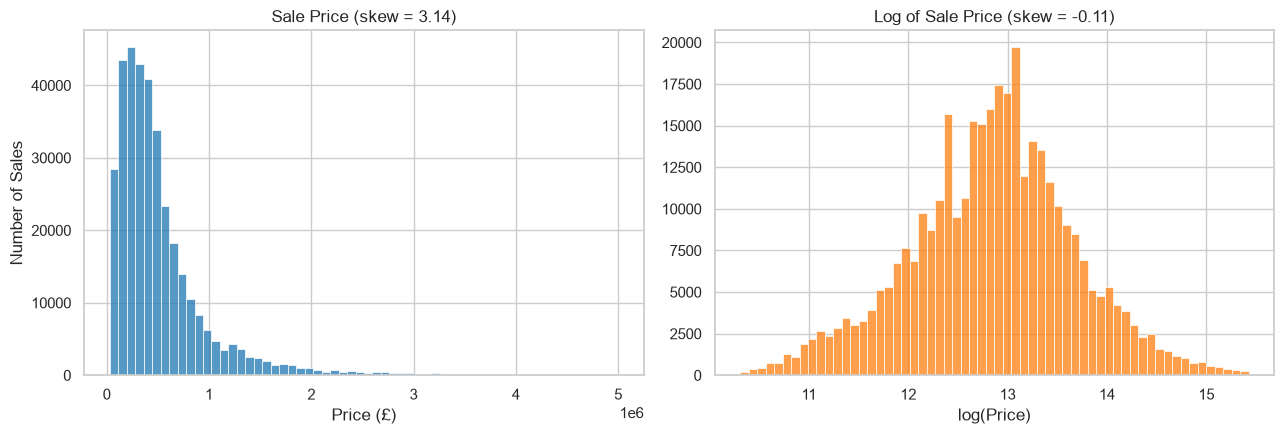

In [14]:
# Price distribution: raw vs log
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(df_clean["history_price"], bins=60, ax=axes[0], color="tab:blue")
axes[0].set_title(f"Sale Price (skew = {df_clean['history_price'].skew():.2f})")
axes[0].set_xlabel("Price (£)")
axes[0].set_ylabel("Number of Sales")

sns.histplot(np.log(df_clean["history_price"]), bins=60, ax=axes[1], color="tab:orange")
axes[1].set_title(f"Log of Sale Price (skew = {np.log(df_clean['history_price']).skew():.2f})")
axes[1].set_xlabel("log(Price)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Explanation:** The left chart shows prices are strongly right-skewed: most sales are moderate and a long tail of expensive homes stretches out. The right chart takes the log, which is far more symmetric. Linear regression works best on roughly symmetric targets, so we model **log(price)**.

Prices are strongly **right-skewed**: most sales are moderate and a long tail of expensive homes pulls the average up. Taking the log makes the distribution much more symmetric. This matters for linear regression, so we will model **log(price)** later.

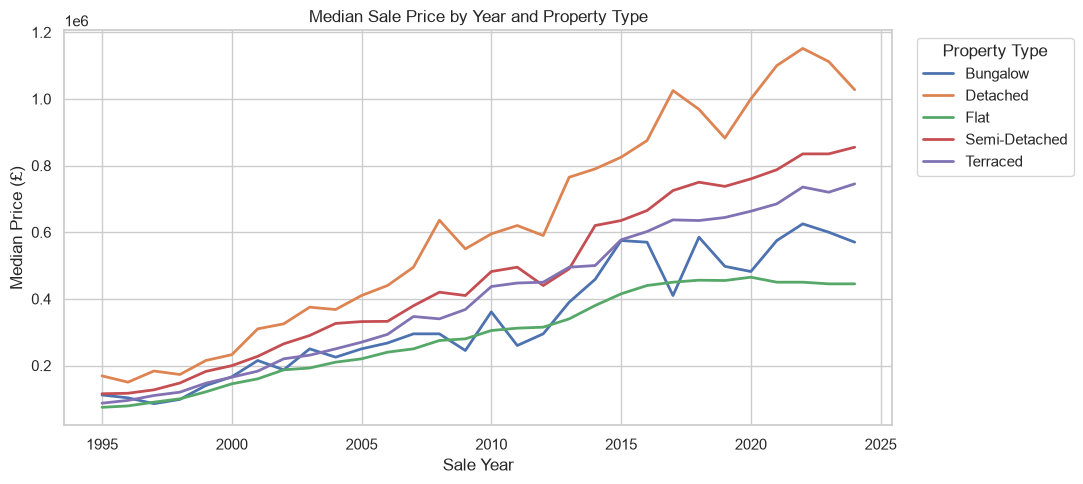

In [15]:
# How prices have changed over time, by property type (median price)
price_by_year = (df_clean[df_clean["sale_year"] >= 1995]
                 .groupby(["sale_year", "propertyType"])["history_price"].median().unstack())

ax = price_by_year.plot(figsize=(11, 5), linewidth=2)
ax.set_title("Median Sale Price by Year and Property Type")
ax.set_xlabel("Sale Year")
ax.set_ylabel("Median Price (£)")
ax.legend(title="Property Type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Explanation:** Plots the median price per year for each property type (the median isn't pulled around by outliers). Prices rose strongly for every type, so `sale_year` must be a feature: a house sold in 1998 isn't comparable to the same house in 2022. This also starts to answer the "how do prices change by property type" question.

In [16]:
# Year-on-year growth in the median price, by property type (how prices "change between now and next year")
yoy = price_by_year.pct_change() * 100
display(yoy.loc[2015:].round(1))

propertyType,Bungalow,Detached,Flat,Semi-Detached,Terraced
sale_year,,,,,
2015,25.40,4.40,9.20,2.40,15.40
2016,-0.90,6.10,6.00,4.70,4.30
2017,-28.10,17.10,2.30,9.00,5.80
2018,42.70,-5.50,1.30,3.40,-0.30
2019,-15.00,-8.90,-0.20,-1.70,1.40
2020,-3.10,13.30,2.20,3.10,2.90
2021,19.30,10.00,-3.20,3.60,3.30
2022,8.70,4.70,0.00,6.00,7.40
2023,-4.00,-3.40,-1.10,0.00,-2.10


**Explanation:** `pct_change()` turns the median prices into the percentage change from the previous year. This is the "now vs next year" idea in numbers: growth isn't constant and differs between property types.

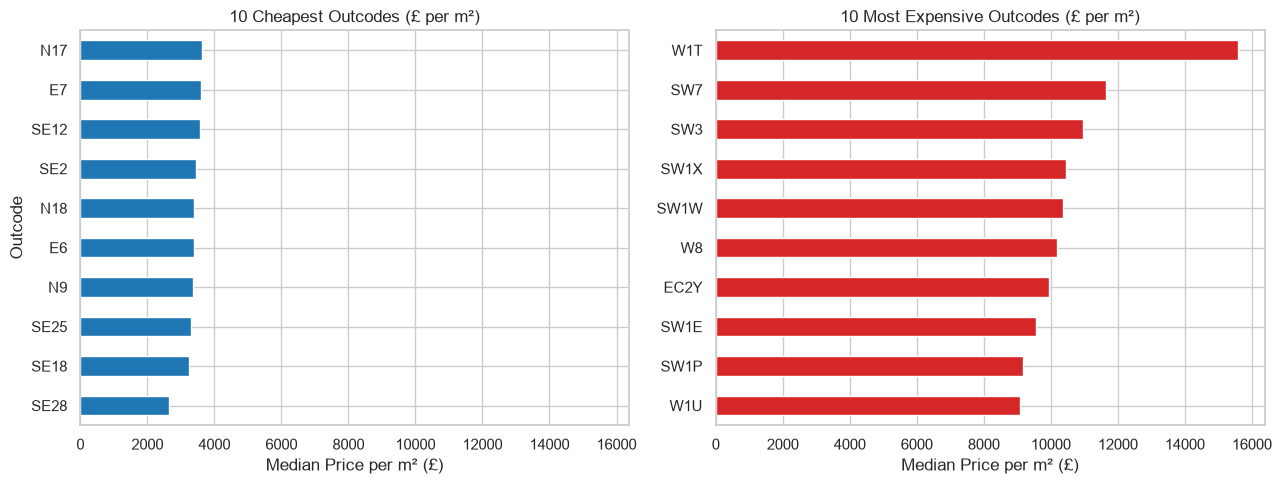

In [17]:
# Location: price per m2 by outcode (areas with at least 500 sales)
outcode_stats = (df_clean.groupby("outcode")
                 .agg(sales=("history_price", "size"),
                      median_price=("history_price", "median"),
                      median_ppsqm=("price_per_sqm", "median"))
                 .query("sales >= 500")
                 .sort_values("median_ppsqm"))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)
outcode_stats.head(10)["median_ppsqm"].plot(kind="barh", ax=axes[0], color="tab:blue")
axes[0].set_title("10 Cheapest Outcodes (£ per m²)")
axes[0].set_xlabel("Median Price per m² (£)")
axes[0].set_ylabel("Outcode")

outcode_stats.tail(10)["median_ppsqm"].plot(kind="barh", ax=axes[1], color="tab:red")
axes[1].set_title("10 Most Expensive Outcodes (£ per m²)")
axes[1].set_xlabel("Median Price per m² (£)")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

**Explanation:** Groups sales by outcode (the first half of a postcode, such as SW3) and compares price per m². Only outcodes with at least 500 sales are kept so a few sales can't make an area look cheap or expensive. Using £ per m² removes the effect of home size. The big gap between the two charts shows location is a major driver of price.

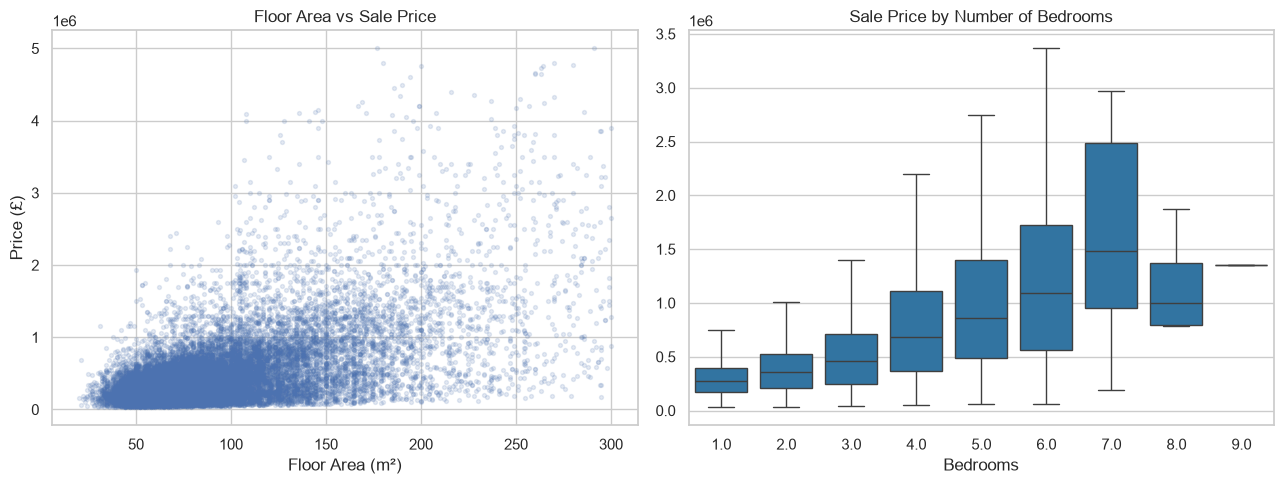

In [18]:
# Size and bedrooms vs price (sample of 20,000 sales so the chart is readable)
sample = df_clean.sample(20_000, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(sample["floorAreaSqM"], sample["history_price"], alpha=0.15, s=8)
axes[0].set_title("Floor Area vs Sale Price")
axes[0].set_xlabel("Floor Area (m²)")
axes[0].set_ylabel("Price (£)")

sns.boxplot(data=sample, x="bedrooms", y="history_price", ax=axes[1], color="tab:blue", showfliers=False)
axes[1].set_title("Sale Price by Number of Bedrooms")
axes[1].set_xlabel("Bedrooms")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Explanation:** A random sample of 20,000 sales is plotted because 400,000 points would be an unreadable blob. The scatter shows price rises with floor area but with a wide spread, since location also matters. The boxplot shows price rises with bedrooms, but the wide boxes mean bedrooms alone is a rough guide.

**Exploration findings:** prices are right-skewed (use a log transform); prices rose for every type (sale year is essential); location has a large effect; bigger homes cost more but with a wide spread; each property can appear several times, which affects the split.

### Exploration findings

- Prices are right-skewed, so a log transform is sensible.
- Prices have risen strongly over time for every property type, so **sale year is a very important feature**. A house sold in 1998 is not comparable to the same house sold in 2022.
- Location matters a great deal: the gap in price per m² between the cheapest and most expensive outcodes is large.
- Larger homes and homes with more bedrooms cost more, but the spread is wide, which is expected as location also drives price.
- Each property can appear several times (one row per sale), which affects how we must split the data.

## 3. Choose X and y variables

**Target (y):** `history_price`, the price a property sold for.

**Features (X):**

| Group | Columns | Type |
|---|---|---|
| Size | `floorAreaSqM` | numeric |
| Rooms | `bedrooms`, `bathrooms`, `livingRooms` | numeric |
| Location | `outcode` | categorical |
| Location | `latitude`, `longitude` | numeric |
| Property | `propertyType`, `tenure`, `currentEnergyRating` | categorical |
| Time | `sale_year` | numeric |

**Columns deliberately left out:**
- `fullAddress`: unique to each property, so it would just memorise houses. We keep it only as a **grouping label** for the train/test split.
- `postcode`: too detailed (tens of thousands of values). `outcode` gives the area without exploding the model.
- `price_per_sqm`: built from the target, which would be **data leakage**.
- `history_date`: replaced by `sale_year`.

**Why sale year is included:** it lets the model learn the price trend over time. For the "next year" question, we can later predict with `sale_year` set to the following year.

In [19]:
numeric_features = ["floorAreaSqM", "bedrooms", "bathrooms", "livingRooms", "latitude", "longitude", "sale_year"]
categorical_features = ["propertyType", "tenure", "currentEnergyRating", "outcode"]

target = "history_price"
group_col = "fullAddress"   # used ONLY to keep the same property out of both train and test

X = df_clean[numeric_features + categorical_features]
y = df_clean[target]
groups = df_clean[group_col]

print("X shape:", X.shape)
print("y shape:", y.shape)
X.head()

X shape: (353413, 11)
y shape: (353413,)


,floorAreaSqM,bedrooms,bathrooms,livingRooms,latitude,longitude,sale_year,propertyType,tenure,currentEnergyRating,outcode
0,45.00,1.00,1.00,1.00,51.52,-0.11,1995,Flat,Leasehold,Unknown,EC4A
1,71.00,2.00,2.00,1.00,51.50,-0.13,1995,Flat,Leasehold,C,SW1P
2,64.00,1.00,1.00,1.00,51.48,-0.09,1995,Flat,Leasehold,D,SE5
3,137.00,4.00,1.00,2.00,51.59,-0.14,1995,Terraced,Freehold,D,N10
4,97.00,2.00,1.00,1.00,51.47,0.01,1995,Terraced,Freehold,D,SE3


**Explanation:** Splits the data into inputs `X` (what the model sees), the answer `y` (the price) and `groups` (the address, used only to keep each house on one side of the split). Numeric and categorical columns are listed separately because the pipeline treats them differently. Left out on purpose: `fullAddress` (unique per house), `postcode` (too detailed), `price_per_sqm` (built from the target, so leakage) and `history_date` (replaced by `sale_year`).

## 4. Check initial regression assumptions

Before fitting, we check the assumptions that can be tested on the raw data. The rest (residual normality, constant variance) can only be checked **after** the model is trained (Step 9).

| Assumption | How we check it now |
|---|---|
| Linear relationship between X and y | Scatter plots and correlations with price / log price |
| No severe multicollinearity | Correlation heatmap and VIF |
| Target roughly normal (helps residuals behave) | Skew of price vs log price |
| Independent observations | Repeated sales of the same property break this, which we handle with a grouped split |

In [20]:
# 4.1 Normality / skew of the target
skew_raw = stats.skew(y)
skew_log = stats.skew(np.log(y))
print(f"Skew of price:      {skew_raw:.2f}")
print(f"Skew of log(price): {skew_log:.2f}")

Skew of price:      3.14
Skew of log(price): -0.11


**Explanation:** Skew measures how lopsided a distribution is (0 is symmetric). Raw price is clearly skewed and log(price) should be near zero, which is the evidence for modelling log(price).

In [21]:
# 4.2 Linearity: relationship of each numeric feature with price and log(price)
check = df_clean[numeric_features].copy()
check["price"] = y
check["log_price"] = np.log(y)

corr = check.corr()[["price", "log_price"]].drop(["price", "log_price"])
display(corr.sort_values("log_price", ascending=False))

,price,log_price
sale_year,0.42,0.65
floorAreaSqM,0.56,0.50
bathrooms,0.48,0.43
bedrooms,0.39,0.38
livingRooms,0.30,0.26
latitude,0.03,0.04
longitude,-0.25,-0.25


**Explanation:** Shows how strongly each numeric feature moves with price and with log(price). If the log column is higher, a straight line fits the log version better, which supports the transform.

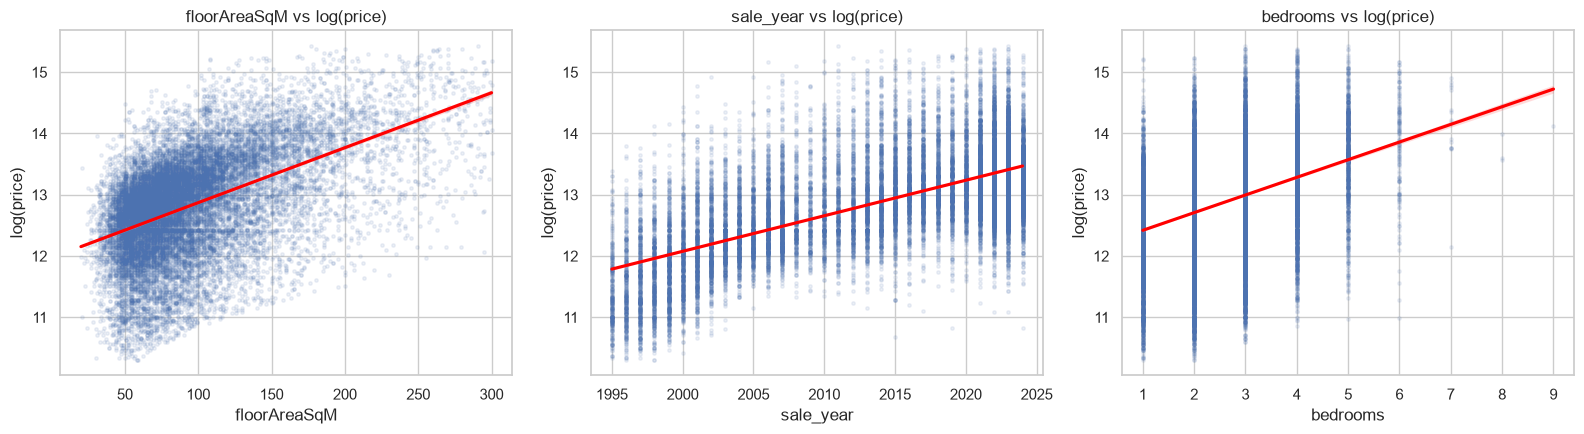

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sample = check.sample(20_000, random_state=RANDOM_STATE)

for ax, col in zip(axes, ["floorAreaSqM", "sale_year", "bedrooms"]):
    sns.regplot(data=sample, x=col, y="log_price", ax=ax,
                scatter_kws={"alpha": 0.1, "s": 6}, line_kws={"color": "red"})
    ax.set_title(f"{col} vs log(price)")
    ax.set_ylabel("log(price)")

plt.tight_layout()
plt.show()

**Explanation:** Draws a regression line through the points for three key features. If the cloud follows the red line, the linear assumption is reasonable. Floor area, sale year and bedrooms should follow it fairly well against log(price).

The relationships with log(price) are close to linear (the red lines follow the clouds), and noticeably closer than with raw price, which supports using the log transform.

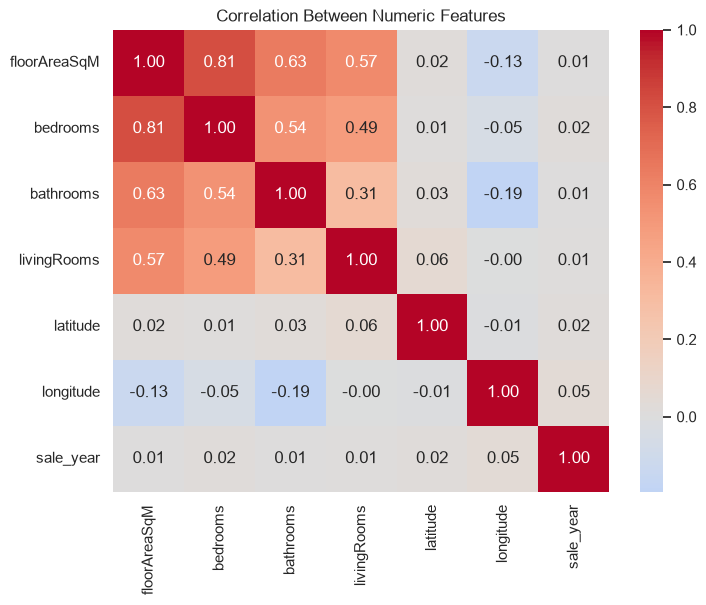

In [23]:
# 4.3 Multicollinearity: correlation heatmap between numeric features
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean[numeric_features].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Numeric Features")
plt.show()

**Explanation:** Checks whether features are correlated with *each other*. Floor area, bedrooms and bathrooms naturally move together. High correlation between features (multicollinearity) makes coefficients unstable and harder to interpret.

In [24]:
# VIF (Variance Inflation Factor) calculated by hand: VIF = 1 / (1 - R²) when predicting one feature from the others
vif_data = df_clean[numeric_features].dropna().sample(50_000, random_state=RANDOM_STATE)

vif_rows = []
for col in numeric_features:
    others = vif_data.drop(columns=col)
    r2 = LinearRegression().fit(others, vif_data[col]).score(others, vif_data[col])
    vif_rows.append({"feature": col, "VIF": 1 / (1 - r2)})

pd.DataFrame(vif_rows).sort_values("VIF", ascending=False)

,feature,VIF
0,floorAreaSqM,4.19
1,bedrooms,3.08
2,bathrooms,1.73
3,livingRooms,1.52
5,longitude,1.06
4,latitude,1.00
6,sale_year,1.00


**Explanation:** The Variance Inflation Factor shows how well each feature can be predicted from the others, calculated as 1 / (1 − R²). Above about 5 to 10 is a warning. A 50,000-row sample keeps it quick. If values are high, Ridge regression (which shrinks coefficients) is a sensible safeguard, which is why it is included.

## 5. Split into training & test data

We use `GroupShuffleSplit` with the property address as the group. This guarantees that **all sales of one property go entirely into train or entirely into test**. A normal random split would put some sales of a house in training and others in test, letting the model "recognise" the house, which makes the scores look better than they really are (data leakage).

We use an 80/20 split.

In [25]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print(f"Training rows: {len(X_train):,} ({len(X_train) / len(X):.0%})")
print(f"Test rows:     {len(X_test):,} ({len(X_test) / len(X):.0%})")

# Safety check: no property should appear in both sets
overlap = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
print("Properties in both train and test:", len(overlap))

Training rows: 283,086 (80%)
Test rows:     70,327 (20%)
Properties in both train and test: 0


**Explanation:** `GroupShuffleSplit` picks 20% of *properties* (not rows) for the test set, so a house is never in both. The overlap check must print 0. The row split is roughly 80/20 rather than exact because properties have different numbers of sales. A plain random split would leak, because the model would see some sales of a house in training and be tested on others.

In [26]:
# Check the two sets look alike (similar price distribution and year range)
summary = pd.DataFrame({
    "Train": y_train.describe(),
    "Test": y_test.describe(),
})
display(summary)
print("Train years:", X_train["sale_year"].min(), "to", X_train["sale_year"].max())
print("Test years: ", X_test["sale_year"].min(), "to", X_test["sale_year"].max())

,Train,Test
count,"283,086.00","70,327.00"
mean,"531,224.38","532,738.27"
std,"518,190.60","512,714.30"
min,"30,000.00","30,000.00"
25%,"227,000.00","230,000.00"
50%,"395,000.00","395,000.00"
75%,"635,000.00","640,000.00"
max,"5,000,000.00","5,000,000.00"


Train years: 1995 to 2024
Test years:  1995 to 2024


**Explanation:** A good split gives two sets with similar price distributions and year ranges. If they differed a lot, the test score wouldn't be a fair measure.

## 6. Create & train the model

We build a **pipeline** so that all preprocessing is learned on the training data only (no leakage) and applied identically to the test data:

- **Numeric columns:** fill missing values with the median (this is where `bathrooms` and `livingRooms` are imputed), then standardise.
- **Categorical columns:** fill missing with the most common value, then one-hot encode. Categories seen only in the test set are ignored safely.
- **Target:** wrapped in `TransformedTargetRegressor` so the model is **trained on log(price)** but **predicts in pounds**.

We train three models for comparison:

1. **Linear Regression**: our main, interpretable baseline.
2. **Ridge Regression**: linear regression with a penalty that handles correlated features.
3. **Random Forest**: a non-linear model, to see how much a linear model is missing.

In [27]:
def build_model(regressor):
    """Preprocessing + regressor, trained on log(price) and predicting in £."""
    numeric_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    categorical_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=20)),
    ])
    preprocess = ColumnTransformer([
        ("num", numeric_pipe, numeric_features),
        ("cat", categorical_pipe, categorical_features),
    ])
    pipe = Pipeline([("prep", preprocess), ("model", regressor)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=np.exp)

models = {
    "Linear Regression": build_model(LinearRegression()),
    "Ridge Regression": build_model(Ridge(alpha=10)),
    "Random Forest": build_model(RandomForestRegressor(
        n_estimators=100, min_samples_leaf=3, max_samples=0.3,
        n_jobs=-1, random_state=RANDOM_STATE)),
}

**Explanation:** `build_model` is a function so all three models get *identical* preprocessing, which keeps the comparison fair. Numbers are median-filled and standardised; categories are mode-filled and one-hot encoded (rare ones grouped, unseen ones ignored). `np.log` / `np.exp` mean the model learns on log prices but predicts in pounds. Ridge's `alpha=10` sets the shrinkage strength. The Random Forest uses 30% of rows per tree and all CPU cores so it trains in reasonable time. Nothing is trained yet; this only defines the models.

In [ ]:
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"Trained: {name}")

Trained: Linear Regression
Trained: Ridge Regression


**Explanation:** `.fit()` is where the learning happens. The pipeline fills gaps, scales, encodes and fits the regression, all on the training set only. The Random Forest will take noticeably longer.

## 7. Make predictions

Each model predicts the sale price for the unseen test set.

In [ ]:
predictions = {name: model.predict(X_test) for name, model in models.items()}

# Look at the first few predictions from the Linear Regression model
results = X_test[["propertyType", "outcode", "floorAreaSqM", "bedrooms", "sale_year"]].copy()
results["Actual (£)"] = y_test
results["Predicted (£)"] = predictions["Linear Regression"]
results["Error (£)"] = results["Predicted (£)"] - results["Actual (£)"]
results["Error (%)"] = results["Error (£)"] / results["Actual (£)"] * 100
display(results.head(10))

**Explanation:** Each model predicts a price for every house in the test set, which it has never seen. The table puts actual and predicted prices side by side for 10 houses, with the error in pounds and as a percentage. A positive error means the model guessed too high.

## 8. Evaluate model performance

Metrics used:

- **MAE** (Mean Absolute Error): the average miss in pounds. Easy to explain.
- **RMSE** (Root Mean Squared Error): also in pounds, but punishes large misses more.
- **R²**: the share of price variation the model explains (1.0 is perfect).
- **R² on log scale**: the score on the scale the model was trained on.
- **Median % error**: how far off a typical prediction is, as a percentage of the real price.

In [ ]:
rows = []
for name, pred in predictions.items():
    pct_err = np.abs(pred - y_test) / y_test * 100
    rows.append({
        "Model": name,
        "MAE (£)": mean_absolute_error(y_test, pred),
        "RMSE (£)": np.sqrt(mean_squared_error(y_test, pred)),
        "R²": r2_score(y_test, pred),
        "R² (log scale)": r2_score(np.log(y_test), np.log(pred)),
        "Median % error": pct_err.median(),
    })

scores = pd.DataFrame(rows).set_index("Model")
display(scores)

**Explanation:** Scores all three models on the same test data. Lower MAE and RMSE are better; higher R² is better. RMSE is always at least MAE, and a big gap means a few large mistakes. The median % error is the most intuitive number: "a typical prediction is off by X%".

In [ ]:
# Compare with training scores to look for overfitting
train_rows = []
for name, model in models.items():
    p = model.predict(X_train)
    train_rows.append({"Model": name,
                       "Train R²": r2_score(y_train, p),
                       "Test R²": scores.loc[name, "R²"]})
train_vs_test = pd.DataFrame(train_rows).set_index("Model")
train_vs_test["Gap"] = train_vs_test["Train R²"] - train_vs_test["Test R²"]
display(train_vs_test)

**Explanation:** Compares the score on data the model trained on with the score on unseen data. A small gap means it generalises well; a large gap means it memorised the training data (overfitting). Random Forests usually show a bigger gap than linear models.

In [ ]:
# Cross-validation for the linear models (grouped so the same property never sits in train and validation)
gkf = GroupKFold(n_splits=5)

for name in ["Linear Regression", "Ridge Regression"]:
    cv_scores = cross_val_score(models[name], X_train, y_train, groups=groups_train,
                                cv=gkf, scoring="r2")
    print(f"{name}: R² per fold = {np.round(cv_scores, 3)} | mean = {cv_scores.mean():.3f} (± {cv_scores.std():.3f})")

**Explanation:** One test split could be lucky or unlucky, so cross-validation trains and tests 5 times on different chunks of the training data. `GroupKFold` keeps each property in one fold only. Similar scores across folds (small ± value) mean the result is stable. The Random Forest is skipped to save time.

In [ ]:
# Actual vs predicted (Linear Regression and Random Forest)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
idx = np.random.RandomState(RANDOM_STATE).choice(len(y_test), size=min(10_000, len(y_test)), replace=False)

for ax, name in zip(axes, ["Linear Regression", "Random Forest"]):
    ax.scatter(y_test.iloc[idx], predictions[name][idx], alpha=0.15, s=8)
    lim = [0, 3_000_000]
    ax.plot(lim, lim, color="red", linestyle="--", label="Perfect prediction")
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f"{name}: Actual vs Predicted")
    ax.set_xlabel("Actual Price (£)")
    ax.set_ylabel("Predicted Price (£)")
    ax.legend()

plt.tight_layout()
plt.show()

**Explanation:** Each dot is one house. A perfect model would put every dot on the red dashed line, so the tighter the cloud hugs it, the better. A fan shape widening at higher prices means the model is less accurate for expensive homes. The axes are limited to £3m so the busy part is readable.

In [ ]:
# Where does the model do well or badly? Error by property type
test_eval = X_test[["propertyType", "outcode"]].copy()
test_eval["actual"] = y_test
test_eval["pred"] = predictions["Linear Regression"]
test_eval["abs_pct_err"] = np.abs(test_eval["pred"] - test_eval["actual"]) / test_eval["actual"] * 100

by_type = test_eval.groupby("propertyType").agg(
    sales=("actual", "size"),
    median_pct_error=("abs_pct_err", "median"),
    mae=("actual", lambda s: mean_absolute_error(s, test_eval.loc[s.index, "pred"]))
).sort_values("median_pct_error")
display(by_type)

**Explanation:** One overall score can hide weak spots, so this breaks the errors down by property type. Types with few sales, such as bungalows, often have bigger errors because the model had less to learn from.

In [ ]:
# Feature importance from the Linear Regression: which inputs move log(price) most? (top 15 by size of coefficient)
lin_pipe = models["Linear Regression"].regressor_
feature_names = lin_pipe.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lin_pipe.named_steps["model"].coef_, index=feature_names)

top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15)
top.sort_values().plot(kind="barh", figsize=(9, 6), color="tab:blue")
plt.title("Top 15 Linear Regression Coefficients (effect on log price)")
plt.xlabel("Coefficient")
plt.show()

**Explanation:** Pulls the learned coefficients out of the fitted pipeline and shows the 15 largest. Because the target is log(price), a coefficient is roughly a percentage change in price. Positive bars raise price, negative bars lower it. Numeric features are standardised so their sizes are comparable; for categories (such as an outcode) the bar is the effect compared with the baseline.

### Evaluation findings

*(Fill these in with your own numbers after running the notebook.)*

- **Best model on the test set:** ___ with R² = ___ and MAE = £___.
- **Typical error:** the median prediction is off by about ___%.
- **Linear vs Random Forest:** if the Random Forest is much better, the true relationships are not fully linear (for example, interactions between location and size), which is a clue for the improvement stage.
- **Overfitting:** compare the Train vs Test R² table. A large gap (common for Random Forest) means overfitting.
- **Where it struggles:** check the error-by-property-type table. Rarer or higher-value types usually have larger percentage errors.
- **Main drivers of price:** check the coefficient chart. Sale year, floor area and location (outcode) should dominate.

### Limitations so far
- Trained only on "typical" London sales (outliers removed), so less reliable for ultra-prime homes.
- The model has no information about condition, garden, parking, or the exact street, which also affect price.
- Past price growth may not repeat, so any "next year" projection is an estimate, not a guarantee.